In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file.endswith(".zip"):
            print(os.path.join(root, file))

/content/drive/MyDrive/AKUN EDIT GW/psmb-main.zip
/content/drive/MyDrive/Tugas magang web Fatur/psmb-sby NEW.zip
/content/drive/MyDrive/Tugas Akhir Fundamental Analisis Data/E-commerce-public-dataset.zip


In [4]:
import zipfile

zip_path = "/content/drive/MyDrive/Tugas Akhir Fundamental Analisis Data/E-commerce-public-dataset.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content")

print("Dataset berhasil diekstrak!")

Dataset berhasil diekstrak!


In [5]:
import os

os.listdir("/content")

['.config', 'drive', 'E-Commerce Public Dataset', 'sample_data']

In [6]:
import pandas as pd
import os

# Lokasi folder dataset
folder_path = "/content/E-Commerce Public Dataset"

# Membaca dataset
orders = pd.read_csv(
    os.path.join(folder_path, "orders_dataset.csv")
)

order_items = pd.read_csv(
    os.path.join(folder_path, "order_items_dataset.csv")
)

customers = pd.read_csv(
    os.path.join(folder_path, "customers_dataset.csv")
)

products = pd.read_csv(
    os.path.join(folder_path, "products_dataset.csv")
)

# Menampilkan data orders
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [7]:
# Memeriksa informasi dataset orders
orders.info()

# Memeriksa jumlah baris dan kolom
print("Jumlah data orders:", orders.shape)

# Memeriksa informasi dataset order_items
order_items.info()

# Memeriksa informasi dataset customers
customers.info()

# Memeriksa informasi dataset products
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB
Jumlah data orders: (99441, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id      

In [8]:
# Memeriksa missing value
print("Missing Value Orders:")
print(orders.isna().sum())

print("\nMissing Value Order Items:")
print(order_items.isna().sum())

print("\nMissing Value Customers:")
print(customers.isna().sum())

print("\nMissing Value Products:")
print(products.isna().sum())

Missing Value Orders:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Missing Value Order Items:
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

Missing Value Customers:
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

Missing Value Products:
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm          

In [9]:
# Memeriksa data duplikat
print("Duplikasi Orders:", orders.duplicated().sum())
print("Duplikasi Order Items:", order_items.duplicated().sum())
print("Duplikasi Customers:", customers.duplicated().sum())
print("Duplikasi Products:", products.duplicated().sum())

Duplikasi Orders: 0
Duplikasi Order Items: 0
Duplikasi Customers: 0
Duplikasi Products: 0


### Cleaning Data

Pada tahap ini, dilakukan pembersihan data berdasarkan permasalahan yang ditemukan pada tahap Assessing Data. Dataset orders memiliki missing value pada beberapa kolom tanggal, sedangkan dataset products memiliki missing value pada kategori dan atribut dimensi produk.

Penanganan missing value dilakukan sesuai kebutuhan analisis. Missing value pada kategori produk diisi dengan nilai `Unknown` agar data produk tetap dapat digunakan. Sementara itu, missing value pada kolom tanggal dan dimensi produk dipertahankan karena tidak seluruhnya menunjukkan kesalahan data.

Selain itu, kolom tanggal pada dataset orders dan order_items diubah ke tipe datetime untuk mempermudah proses analisis berdasarkan waktu. Tidak dilakukan penghapusan data duplikat karena tidak ditemukan data duplikat pada dataset yang diperiksa.

In [10]:
# Membuat salinan dataset
orders_clean = orders.copy()
order_items_clean = order_items.copy()
customers_clean = customers.copy()
products_clean = products.copy()

# Mengubah kolom tanggal pada orders menjadi datetime
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    orders_clean[column] = pd.to_datetime(
        orders_clean[column],
        errors="coerce"
    )

# Mengubah kolom tanggal pada order_items
order_items_clean["shipping_limit_date"] = pd.to_datetime(
    order_items_clean["shipping_limit_date"],
    errors="coerce"
)

# Mengisi missing value kategori produk
products_clean["product_category_name"] = (
    products_clean["product_category_name"].fillna("Unknown")
)

# Memeriksa hasil cleaning
print("Missing value Orders:")
print(orders_clean.isna().sum())

print("\nMissing value Products:")
print(products_clean.isna().sum())

print("\nTipe data tanggal:")
print(orders_clean[date_columns].dtypes)

Missing value Orders:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Missing value Products:
product_id                      0
product_category_name           0
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Tipe data tanggal:
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


In [11]:
orders_clean["order_estimated_delivery_date"] = pd.to_datetime(
    orders_clean["order_estimated_delivery_date"],
    errors="coerce"
)

print(orders_clean["order_estimated_delivery_date"].dtype)

datetime64[ns]


## Exploratory Data Analysis (EDA)

Pada tahap Exploratory Data Analysis (EDA), dilakukan eksplorasi data untuk memperoleh informasi dan menjawab pertanyaan bisnis yang telah ditentukan. Analisis dilakukan dengan menggabungkan data pesanan dan detail produk, kemudian melakukan agregasi berdasarkan waktu, kategori produk, pelanggan, dan wilayah geografis.

Tahap ini bertujuan untuk mengetahui tren penjualan, kategori produk dengan kontribusi penjualan terbesar, segmentasi pelanggan, serta distribusi penjualan berdasarkan wilayah.

In [12]:
# Menggabungkan orders dengan order_items
df = orders_clean.merge(
    order_items_clean,
    on="order_id",
    how="inner"
)

# Menggabungkan dengan data customers
df = df.merge(
    customers_clean,
    on="customer_id",
    how="inner"
)

# Menggabungkan dengan data products
df = df.merge(
    products_clean,
    on="product_id",
    how="left"
)

# Memfilter pesanan delivered
df = df[df["order_status"] == "delivered"].copy()

# Memfilter periode Januari 2017 - Agustus 2018
df = df[
    (df["order_purchase_timestamp"] >= "2017-01-01") &
    (df["order_purchase_timestamp"] < "2018-09-01")
].copy()

# Menampilkan data
df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,...,customer_city,customer_state,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,1,87285b34884572647811a353c7ac498a,...,sao paulo,SP,utilidades_domesticas,40.0,268.0,4.0,500.0,19.0,8.0,13.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,1,595fac2a385ac33a80bd5114aec74eb8,...,barreiras,BA,perfumaria,29.0,178.0,1.0,400.0,19.0,13.0,19.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,1,aa4383b373c6aca5d8797843e5594415,...,vianopolis,GO,automotivo,46.0,232.0,1.0,420.0,24.0,19.0,21.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,1,d0b61bfb1de832b15ba9d266ca96e5b0,...,sao goncalo do amarante,RN,pet_shop,59.0,468.0,3.0,450.0,30.0,10.0,20.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,1,65266b2da20d04dbe00c5c2d3bb7859e,...,santo andre,SP,papelaria,38.0,316.0,4.0,250.0,51.0,15.0,15.0


In [13]:
print("Jumlah baris data:", df.shape[0])
print("Jumlah kolom data:", df.shape[1])

df.info()

Jumlah baris data: 109880
Jumlah kolom data: 26
<class 'pandas.core.frame.DataFrame'>
Index: 109880 entries, 0 to 112649
Data columns (total 26 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   order_id                       109880 non-null  object        
 1   customer_id                    109880 non-null  object        
 2   order_status                   109880 non-null  object        
 3   order_purchase_timestamp       109880 non-null  datetime64[ns]
 4   order_approved_at              109865 non-null  datetime64[ns]
 5   order_delivered_carrier_date   109878 non-null  datetime64[ns]
 6   order_delivered_customer_date  109872 non-null  datetime64[ns]
 7   order_estimated_delivery_date  109880 non-null  datetime64[ns]
 8   order_item_id                  109880 non-null  int64         
 9   product_id                     109880 non-null  object        
 10  seller_id                

### Analisis Tren Penjualan Bulanan

Analisis ini dilakukan untuk mengetahui perkembangan penjualan Olist dari bulan ke bulan selama periode Januari 2017 hingga Agustus 2018. Metrik yang digunakan adalah jumlah pesanan unik dan total nilai penjualan produk (revenue).

Hasil analisis ini dapat digunakan untuk mengidentifikasi pola pertumbuhan atau penurunan penjualan serta membantu bisnis dalam menentukan strategi penjualan pada periode berikutnya.

In [14]:
# Mengelompokkan penjualan berdasarkan bulan
monthly_sales = df.groupby(
    df["order_purchase_timestamp"].dt.to_period("M")
).agg(
    total_orders=("order_id", "nunique"),
    total_revenue=("price", "sum")
).reset_index()

# Mengubah periode menjadi string
monthly_sales["order_purchase_timestamp"] = (
    monthly_sales["order_purchase_timestamp"].astype(str)
)

# Menampilkan hasil
monthly_sales

,order_purchase_timestamp,total_orders,total_revenue
0,2017-01,750,111798.36
1,2017-02,1653,234223.40
2,2017-03,2546,359198.85
3,2017-04,2303,340669.68
4,2017-05,3546,489338.25
5,2017-06,3135,421923.37
6,2017-07,3872,481604.52
7,2017-08,4193,554699.70
8,2017-09,4150,607399.67
9,2017-10,4478,648247.65


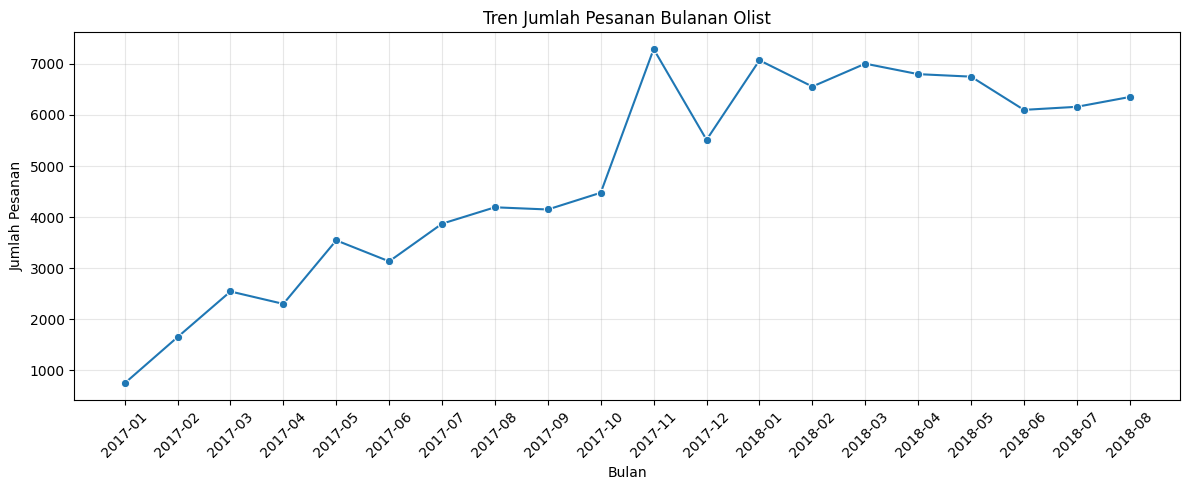

In [17]:
# Visualisasi tren jumlah pesanan bulanan
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_sales,
    x="order_purchase_timestamp",
    y="total_orders",
    marker="o"
)

plt.title("Tren Jumlah Pesanan Bulanan Olist")
plt.xlabel("Bulan")
plt.ylabel("Jumlah Pesanan")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

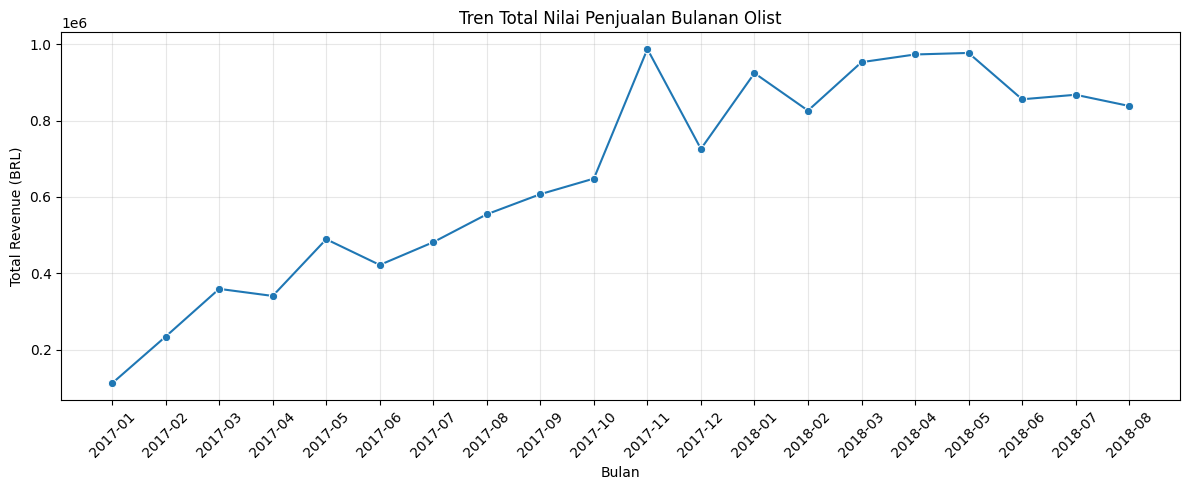

In [18]:
# Visualisasi tren revenue bulanan
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_sales,
    x="order_purchase_timestamp",
    y="total_revenue",
    marker="o"
)

plt.title("Tren Total Nilai Penjualan Bulanan Olist")
plt.xlabel("Bulan")
plt.ylabel("Total Revenue (BRL)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Analisis Performa Penjualan Berdasarkan Kategori Produk

Analisis ini bertujuan untuk mengetahui kategori produk yang memberikan kontribusi nilai penjualan terbesar selama periode Januari 2017 hingga Agustus 2018.

Analisis dilakukan dengan mengelompokkan data berdasarkan kategori produk, kemudian menghitung total nilai penjualan (revenue) dan jumlah produk yang terjual. Hasil analisis dapat digunakan untuk menentukan kategori produk yang perlu diprioritaskan dalam strategi penjualan.

In [19]:
# Menghitung revenue dan jumlah produk per kategori
category_sales = df.groupby(
    "product_category_name"
).agg(
    total_revenue=("price", "sum"),
    total_sold=("order_item_id", "count")
).reset_index()

# Mengurutkan berdasarkan revenue terbesar
category_sales = category_sales.sort_values(
    by="total_revenue",
    ascending=False
)

# Menampilkan 10 kategori teratas
category_sales.head(10)

,product_category_name,total_revenue,total_sold
12,beleza_saude,1229557.50,9422
67,relogios_presentes,1163465.91,5855
14,cama_mesa_banho,1022955.77,10945
33,esporte_lazer,952840.40,8414
45,informatica_acessorios,888055.59,7632
55,moveis_decoracao,706237.17,8095
73,utilidades_domesticas,614341.62,6783
27,cool_stuff,609158.00,3711
9,automotivo,577838.39,4132
41,ferramentas_jardim,469135.40,4263


In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

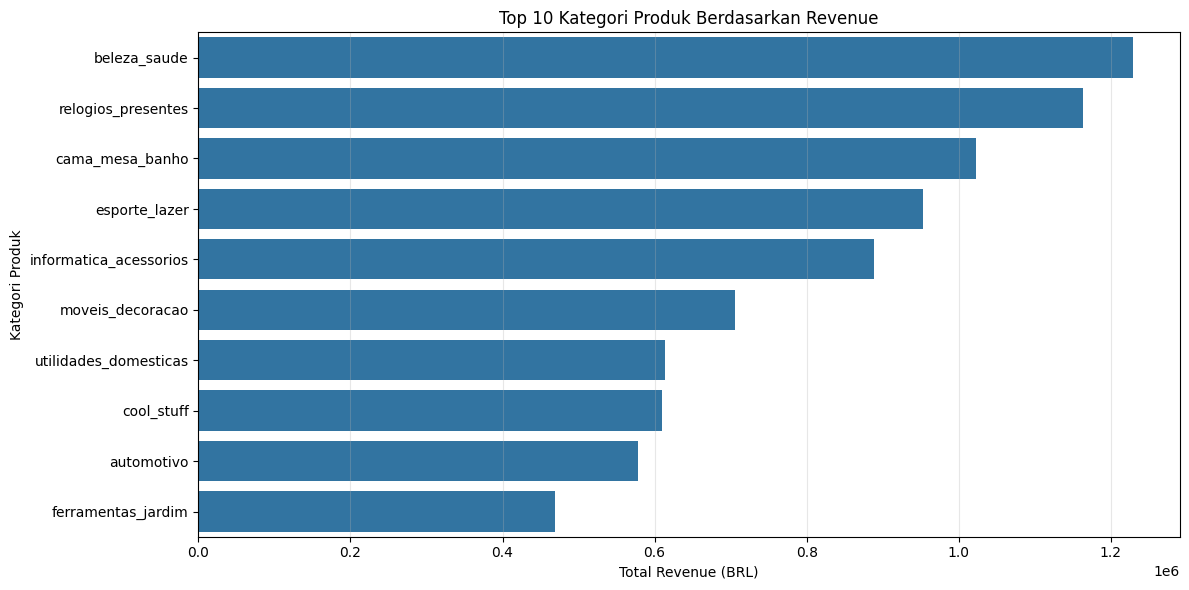

In [20]:
# Mengambil 10 kategori dengan revenue tertinggi
top_category = category_sales.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_category,
    x="total_revenue",
    y="product_category_name"
)

plt.title("Top 10 Kategori Produk Berdasarkan Revenue")
plt.xlabel("Total Revenue (BRL)")
plt.ylabel("Kategori Produk")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

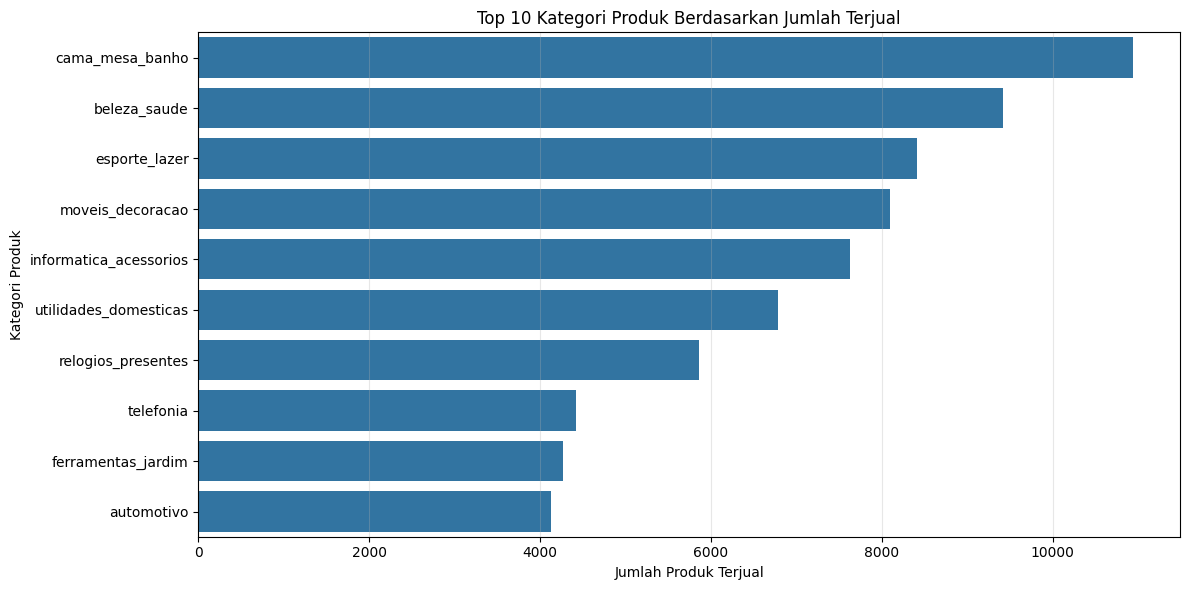

In [21]:
# Mengambil 10 kategori dengan jumlah produk terjual tertinggi
top_sold = category_sales.sort_values(
    by="total_sold",
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_sold,
    x="total_sold",
    y="product_category_name"
)

plt.title("Top 10 Kategori Produk Berdasarkan Jumlah Terjual")
plt.xlabel("Jumlah Produk Terjual")
plt.ylabel("Kategori Produk")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### RFM Analysis

RFM Analysis merupakan teknik analisis yang digunakan untuk melakukan segmentasi pelanggan berdasarkan tiga aspek, yaitu Recency, Frequency, dan Monetary.

Analisis ini dilakukan untuk mengetahui karakteristik pelanggan berdasarkan aktivitas pembelian mereka. Recency menunjukkan seberapa baru pelanggan melakukan pembelian, Frequency menunjukkan seberapa sering pelanggan melakukan transaksi, sedangkan Monetary menunjukkan total pengeluaran pelanggan.

Dalam proyek ini, segmentasi RFM dilakukan menggunakan teknik binning dengan membagi pelanggan ke dalam empat kelompok skor pada masing-masing aspek. Hasil analisis dapat digunakan untuk menentukan strategi pemasaran yang lebih tepat berdasarkan perilaku pelanggan.

In [22]:
# Menentukan tanggal acuan analisis
reference_date = df["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

# Menghitung RFM berdasarkan pelanggan unik
rfm = df.groupby("customer_unique_id").agg(
    Recency=("order_purchase_timestamp", "max"),
    Frequency=("order_id", "nunique"),
    Monetary=("price", "sum")
).reset_index()

# Menghitung Recency dalam hari
rfm["Recency"] = (
    reference_date - rfm["Recency"]
).dt.days

# Menampilkan hasil RFM
rfm.head()

,customer_unique_id,Recency,Frequency,Monetary
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,129.90
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,18.90
2,0000f46a3911fa3c0805444483337064,537,1,69.00
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,25.99
4,0004aac84e0df4da2b147fca70cf8255,288,1,180.00


In [23]:
# Membuat skor RFM dengan teknik binning

rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    4,
    labels=[4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
).astype(int)

# Membuat gabungan skor RFM
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

rfm.head()

,customer_unique_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,129.90,4,1,3,413
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,18.90,3,1,1,311
2,0000f46a3911fa3c0805444483337064,537,1,69.00,1,1,2,112
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,25.99,2,1,1,211
4,0004aac84e0df4da2b147fca70cf8255,288,1,180.00,2,1,4,214


In [24]:
rfm.describe()

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
count,93104.000000,93104.000000,93104.000000,93104.00000,93104.00000,93104.00000
mean,236.702924,1.033371,141.573156,2.50000,2.50000,2.50000
std,150.942219,0.209012,215.760366,1.11804,1.11804,1.11804
min,1.000000,1.000000,0.850000,1.00000,1.00000,1.00000
25%,114.000000,1.000000,47.650000,1.75000,1.75000,1.75000
50%,218.000000,1.000000,89.700000,2.50000,2.50000,2.50000
75%,345.000000,1.000000,154.175000,3.25000,3.25000,3.25000
max,602.000000,15.000000,13440.000000,4.00000,4.00000,4.00000


In [25]:
# Menghitung rata-rata skor RFM
rfm[["R_Score", "F_Score", "M_Score"]].mean()

,0
R_Score,2.5
F_Score,2.5
M_Score,2.5


### Segmentasi Pelanggan Berdasarkan RFM

Pada tahap ini, pelanggan dikelompokkan berdasarkan skor Recency, Frequency, dan Monetary menggunakan metode manual grouping.

Segmentasi dilakukan untuk mengidentifikasi pelanggan yang memiliki nilai tinggi, pelanggan yang berpotensi melakukan pembelian ulang, serta pelanggan yang perlu mendapatkan perhatian khusus. Hasil segmentasi dapat digunakan sebagai dasar dalam menentukan strategi pemasaran dan peningkatan loyalitas pelanggan.

In [26]:
# Membuat segmentasi pelanggan berdasarkan skor RFM

conditions = [
    (rfm["R_Score"] >= 3) &
    (rfm["F_Score"] >= 3) &
    (rfm["M_Score"] >= 3),

    (rfm["R_Score"] >= 3) &
    (rfm["F_Score"] >= 2),

    (rfm["M_Score"] == 4),

    (rfm["R_Score"] <= 2) &
    (rfm["F_Score"] >= 2)
]

categories = [
    "Champions",
    "Loyal Customers",
    "Big Spenders",
    "At Risk"
]

rfm["Customer_Segment"] = np.select(
    conditions,
    categories,
    default="Other Customers"
)

# Menampilkan data segmentasi
rfm.head()

,customer_unique_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Customer_Segment
0,0000366f3b9a7992bf8c76cfdf3221e2,112,1,129.90,4,1,3,413,Other Customers
1,0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,18.90,3,1,1,311,Other Customers
2,0000f46a3911fa3c0805444483337064,537,1,69.00,1,1,2,112,Other Customers
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,25.99,2,1,1,211,Other Customers
4,0004aac84e0df4da2b147fca70cf8255,288,1,180.00,2,1,4,214,Big Spenders


In [27]:
# Menghitung jumlah pelanggan setiap segmentasi
segment_counts = rfm["Customer_Segment"].value_counts().reset_index()

segment_counts.columns = [
    "Customer_Segment",
    "Total_Customers"
]

segment_counts

,Customer_Segment,Total_Customers
0,At Risk,26099
1,Loyal Customers,22875
2,Other Customers,17762
3,Big Spenders,14297
4,Champions,12071


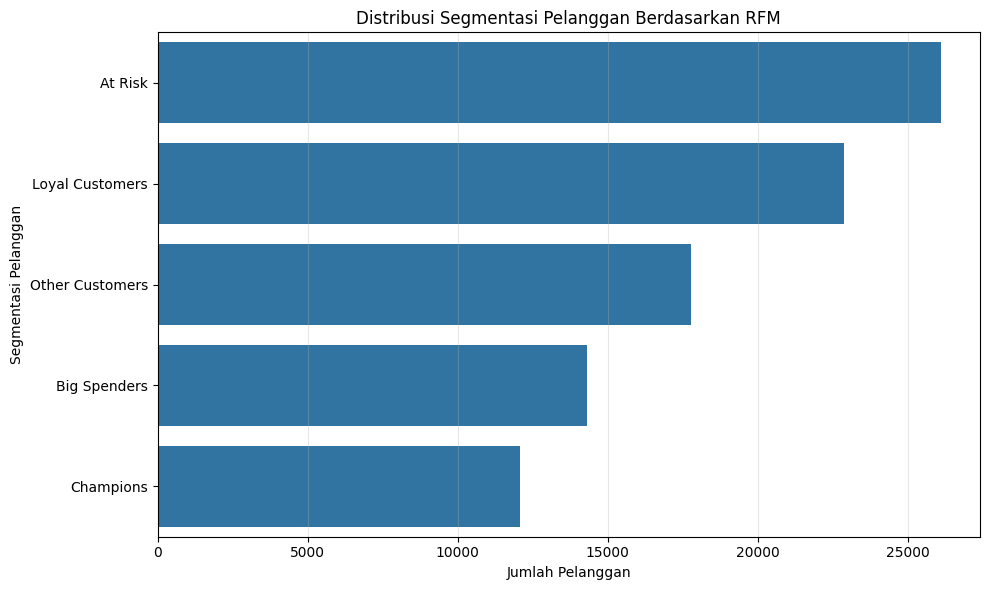

In [28]:
# Visualisasi segmentasi pelanggan

plt.figure(figsize=(10, 6))

sns.barplot(
    data=segment_counts,
    x="Total_Customers",
    y="Customer_Segment"
)

plt.title("Distribusi Segmentasi Pelanggan Berdasarkan RFM")
plt.xlabel("Jumlah Pelanggan")
plt.ylabel("Segmentasi Pelanggan")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## Conclusion & Recommendation

### Kesimpulan

Berdasarkan hasil Exploratory Data Analysis dan RFM Analysis pada dataset E-Commerce Public Dataset Olist, diperoleh beberapa kesimpulan:

1. Analisis tren penjualan bulanan menunjukkan adanya perubahan jumlah pesanan dari waktu ke waktu. Periode November 2017 menjadi salah satu periode dengan jumlah pesanan tertinggi.
2. Kategori produk `beleza_saude` memiliki total nilai penjualan tertinggi, sedangkan kategori `cama_mesa_banho` memiliki jumlah produk terjual tertinggi.
3. Hasil RFM Analysis menunjukkan bahwa rata-rata pelanggan hanya melakukan sekitar 1,03 transaksi. Hal ini mengindikasikan bahwa sebagian besar pelanggan belum melakukan pembelian berulang.
4. Segmentasi RFM menunjukkan bahwa segmen At Risk memiliki jumlah pelanggan terbesar, sehingga perlu mendapatkan perhatian dalam strategi retensi pelanggan.

### Recommendation

Berdasarkan hasil analisis, rekomendasi action item yang dapat dilakukan adalah:

1. **Meningkatkan retensi pelanggan:** Memberikan promo pembelian ulang, voucher diskon, atau email marketing kepada pelanggan dalam segmen At Risk.
2. **Memprioritaskan kategori produk unggulan:** Mempertahankan ketersediaan produk pada kategori `beleza_saude` dan `cama_mesa_banho` karena memiliki kontribusi penjualan dan volume transaksi yang tinggi.
3. **Meningkatkan loyalitas pelanggan:** Membuat program loyalitas atau reward bagi pelanggan yang melakukan transaksi berulang.
4. **Melakukan evaluasi penjualan secara berkala:** Memantau tren penjualan bulanan untuk mengetahui perubahan performa bisnis dan menentukan strategi penjualan selanjutnya.

In [29]:
import os

# Membuat folder submission
submission_path = "/content/submission"

dashboard_path = os.path.join(
    submission_path,
    "dashboard"
)

data_path = os.path.join(
    dashboard_path,
    "data"
)

os.makedirs(data_path, exist_ok=True)

# Menyimpan dataset hasil analisis
df.to_csv(
    os.path.join(data_path, "main_data.csv"),
    index=False
)

monthly_sales.to_csv(
    os.path.join(data_path, "monthly_sales.csv"),
    index=False
)

category_sales.to_csv(
    os.path.join(data_path, "category_sales.csv"),
    index=False
)

rfm.to_csv(
    os.path.join(data_path, "rfm_data.csv"),
    index=False
)

segment_counts.to_csv(
    os.path.join(data_path, "segment_counts.csv"),
    index=False
)

print("Semua file CSV berhasil disimpan!")

Semua file CSV berhasil disimpan!


In [30]:
!pip install streamlit plotly -q

In [31]:

%%writefile /content/submission/dashboard/dashboard.py

import streamlit as st
import pandas as pd
import plotly.express as px
import os

# Konfigurasi halaman
st.set_page_config(
    page_title="Olist E-Commerce Dashboard",
    page_icon="📊",
    layout="wide"
)

# Membaca data
BASE_DIR = os.path.dirname(__file__)
DATA_DIR = os.path.join(BASE_DIR, "data")

df = pd.read_csv(os.path.join(DATA_DIR, "main_data.csv"))
category_sales = pd.read_csv(
    os.path.join(DATA_DIR, "category_sales.csv")
)
segment_counts = pd.read_csv(
    os.path.join(DATA_DIR, "segment_counts.csv")
)

# Mengubah tipe data tanggal
df["order_purchase_timestamp"] = pd.to_datetime(
    df["order_purchase_timestamp"],
    errors="coerce"
)

# Judul dashboard
st.title("📊 Olist E-Commerce Dashboard")
st.caption(
    "Dashboard analisis penjualan dan perilaku pelanggan "
    "Olist periode 2017–2018"
)

# Sidebar filter tanggal
st.sidebar.header("Filter Data")

min_date = df["order_purchase_timestamp"].min().date()
max_date = df["order_purchase_timestamp"].max().date()

date_range = st.sidebar.date_input(
    "Pilih rentang tanggal",
    value=(min_date, max_date),
    min_value=min_date,
    max_value=max_date
)

if len(date_range) == 2:
    start_date, end_date = date_range

    filtered_df = df[
        (df["order_purchase_timestamp"].dt.date >= start_date) &
        (df["order_purchase_timestamp"].dt.date <= end_date)
    ].copy()
else:
    filtered_df = df.copy()

# Menghitung KPI
total_revenue = filtered_df["price"].sum()
total_orders = filtered_df["order_id"].nunique()
total_customers = filtered_df["customer_unique_id"].nunique()

# KPI Cards
col1, col2, col3 = st.columns(3)

col1.metric(
    "Total Revenue",
    f"R$ {total_revenue:,.2f}"
)

col2.metric(
    "Total Orders",
    f"{total_orders:,}"
)

col3.metric(
    "Total Customers",
    f"{total_customers:,}"
)

st.divider()

# Grafik tren penjualan bulanan
st.subheader("Tren Penjualan Bulanan")

monthly_data = filtered_df.groupby(
    filtered_df["order_purchase_timestamp"].dt.to_period("M")
).agg(
    total_orders=("order_id", "nunique"),
    total_revenue=("price", "sum")
).reset_index()

monthly_data["month"] = (
    monthly_data["order_purchase_timestamp"].astype(str)
)

fig_monthly = px.line(
    monthly_data,
    x="month",
    y="total_revenue",
    markers=True,
    title="Total Revenue per Bulan",
    labels={
        "month": "Bulan",
        "total_revenue": "Revenue (BRL)"
    }
)

st.plotly_chart(fig_monthly, use_container_width=True)

# Grafik kategori produk
st.subheader("Performa Kategori Produk")

top_category = category_sales.sort_values(
    "total_revenue",
    ascending=False
).head(10)

fig_category = px.bar(
    top_category,
    x="total_revenue",
    y="product_category_name",
    orientation="h",
    title="Top 10 Kategori Berdasarkan Revenue",
    labels={
        "total_revenue": "Revenue (BRL)",
        "product_category_name": "Kategori Produk"
    }
)

fig_category.update_layout(
    yaxis={"categoryorder": "total ascending"}
)

st.plotly_chart(fig_category, use_container_width=True)

# Grafik segmentasi pelanggan
st.subheader("Segmentasi Pelanggan RFM")

fig_segment = px.bar(
    segment_counts,
    x="Customer_Segment",
    y="Total_Customers",
    title="Distribusi Segmentasi Pelanggan",
    labels={
        "Customer_Segment": "Segmen Pelanggan",
        "Total_Customers": "Jumlah Pelanggan"
    }
)

st.plotly_chart(fig_segment, use_container_width=True)

# Tabel data
st.subheader("Detail Data Penjualan")

st.dataframe(
    filtered_df[
        [
            "order_id",
            "customer_unique_id",
            "order_purchase_timestamp",
            "product_category_name",
            "price"
        ]
    ].head(100),
    use_container_width=True
)

st.caption(
    "Data bersumber dari Olist Brazilian E-Commerce Public Dataset."
)


Writing /content/submission/dashboard/dashboard.py


In [32]:

%%writefile /content/submission/requirements.txt

pandas
numpy
matplotlib
seaborn
streamlit
plotly


Writing /content/submission/requirements.txt


In [33]:

%%writefile /content/submission/README.md

# Olist E-Commerce Data Analysis

## Deskripsi
Proyek ini merupakan analisis data pada Olist Brazilian
E-Commerce Public Dataset untuk memahami tren penjualan,
performa kategori produk, dan perilaku pelanggan.

## Analisis
- Data Wrangling
- Exploratory Data Analysis (EDA)
- Analisis tren penjualan bulanan
- Analisis kategori produk
- RFM Analysis
- Segmentasi pelanggan
- Dashboard interaktif menggunakan Streamlit

## Struktur Folder

submission/
├── dashboard/
│   ├── dashboard.py
│   └── data/
│       ├── main_data.csv
│       ├── monthly_sales.csv
│       ├── category_sales.csv
│       ├── rfm_data.csv
│       └── segment_counts.csv
├── notebook.ipynb
├── README.md
└── requirements.txt

## Cara Menjalankan Dashboard

1. Install Python.
2. Buka terminal pada folder dashboard.
3. Install library:

   pip install -r ../requirements.txt

4. Jalankan dashboard:

   streamlit run dashboard.py

5. Dashboard akan terbuka di browser.

## Dataset
Olist Brazilian E-Commerce Public Dataset


Writing /content/submission/README.md
